# Short-Horizon Predictive Analysis of Order Book Signals

This notebook explores whether order book signals predict short-horizon midprice movements in CME E-mini S&P 500 (ES) futures.

Using cleaned order book data from 1 day, October 8, 2026, we evaluate order book imbalance (OBI), microprice, signal decay, and preliminary execution feasibility.

This is an initial single-session analysis intended to establish the research methodology before extending the analysis across multiple trading days.

### 1. Data Loading and Feature Construction

Load cleaned ES futures order book data using the project's existing data pipeline.

Calculate midprice and order book imbalance (OBI), then sample the latest observation from each minute for preliminary analysis.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from finm37000_grp2 import config
from finm37000_grp2.features import (
    calculate_microprice,
    calculate_midprice,
    calculate_obi,
    calculate_spread,
)

# Load cleaned development sample
df = pd.read_parquet(config.PROCESSED_DIR / "ES" / "2026-10-08.parquet")
# Exclude locked quotes and contract-roll observations
df = df.loc[~df["locked"] & ~df["roll"]].copy()

# Calculate order-book features
df["midprice"] = calculate_midprice(df["bid_px"], df["ask_px"])
df["obi"] = calculate_obi(df["bid_sz"], df["ask_sz"])

# Take the last available observation each minute
minute_df = df.resample("1min").last().dropna(subset=["midprice", "obi"])

print(minute_df[["midprice", "obi"]].head())
print(f"\nNumber of minute observations: {len(minute_df)}")

                           midprice       obi
ts_event                                     
2026-10-08 13:30:00+00:00  7824.875  0.419355
2026-10-08 13:31:00+00:00  7828.125  0.022222
2026-10-08 13:32:00+00:00  7827.875 -0.309091
2026-10-08 13:33:00+00:00  7829.375  0.142857
2026-10-08 13:34:00+00:00  7831.875  0.125000

Number of minute observations: 405


### 2. Initial Predictability Test: One-Minute Price Movements

Evaluate the relationship between current OBI and the subsequent one-minute midprice movement in ticks.

This provides an initial measure of whether order book imbalance contains predictive information about future price movements.

**Research Question:** RQ1 — Predictability

In [2]:
# Calculate the midprice movement over the next minute
minute_df["future_move_ticks"] = (
    minute_df["midprice"].shift(-1) - minute_df["midprice"]
) / 0.25

# Remove the final row, which has no future price movement
analysis_df = minute_df.dropna(subset=["future_move_ticks"]).copy()

print(analysis_df[["midprice", "obi", "future_move_ticks"]].head())

# Correlation between current OBI and next-minute price movement
correlation = analysis_df["obi"].corr(analysis_df["future_move_ticks"])

print(f"\nOBI vs. next-minute price movement correlation: {correlation:.4f}")
print(f"Number of observations: {len(analysis_df)}")

                           midprice       obi  future_move_ticks
ts_event                                                        
2026-10-08 13:30:00+00:00  7824.875  0.419355               13.0
2026-10-08 13:31:00+00:00  7828.125  0.022222               -1.0
2026-10-08 13:32:00+00:00  7827.875 -0.309091                6.0
2026-10-08 13:33:00+00:00  7829.375  0.142857               10.0
2026-10-08 13:34:00+00:00  7831.875  0.125000              -20.0

OBI vs. next-minute price movement correlation: 0.0473
Number of observations: 404


### 2.1 Visualizing OBI and Future Price Movements

Plot OBI against next-minute midprice movements to examine the direction, strength, and dispersion of the predictive relationship.

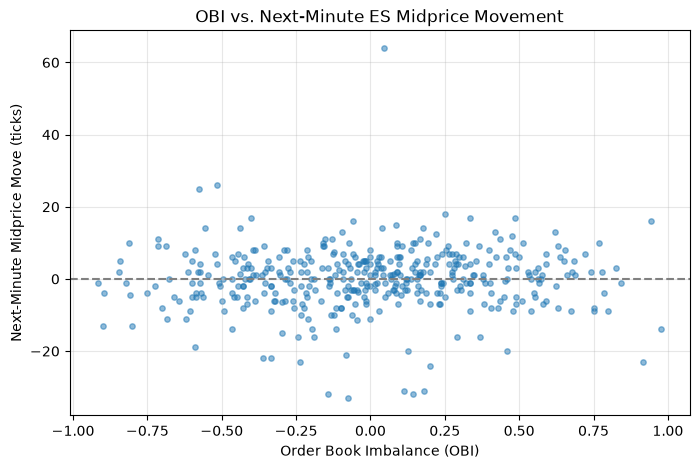

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    analysis_df["obi"],
    analysis_df["future_move_ticks"],
    alpha=0.5,
    s=15,
)

plt.xlabel("Order Book Imbalance (OBI)")
plt.ylabel("Next-Minute Midprice Move (ticks)")
plt.title("OBI vs. Next-Minute ES Midprice Movement")
plt.axhline(0, color="gray", linestyle="--")
plt.grid(alpha=0.3)

plt.show()

### 3. Predictive Price Movements Across OBI Levels

Divide observations into five OBI groups and compare their average subsequent one-minute midprice movements in ticks.

**Research Question:** RQ1 — Predictability

obi_group
Very Low     0.123457
Low         -1.701220
Medium       1.025000
High         0.202381
Very High    0.240260
Name: future_move_ticks, dtype: float64


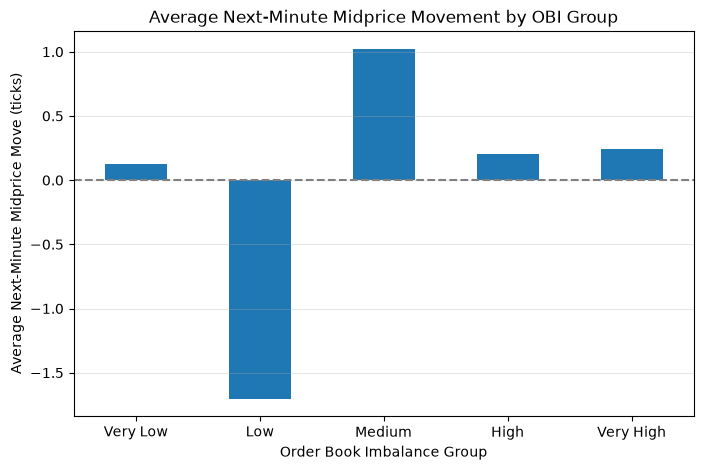

In [4]:
# Divide OBI into five groups, from lowest to highest
analysis_df["obi_group"] = pd.qcut(
    analysis_df["obi"], q=5, labels=["Very Low", "Low", "Medium", "High", "Very High"]
)

# Calculate average next-minute price movement for each group
group_pm = analysis_df.groupby("obi_group", observed=True)["future_move_ticks"].mean()

print(group_pm)

# Plot average future price movement
plt.figure(figsize=(8, 5))

group_pm.plot(kind="bar")

plt.xlabel("Order Book Imbalance Group")
plt.ylabel("Average Next-Minute Midprice Move (ticks)")
plt.title("Average Next-Minute Midprice Movement by OBI Group")
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

### 4. Short-Horizon Predictability

Evaluate the correlation between OBI and future midprice movements across multiple forecast horizons.

This analysis investigates how quickly predictive information contained in the order book diminishes.

**Research Questions:** RQ1 — Predictability; RQ3 — Alpha Decay

In [5]:
# Keep the latest observation for every second
second_df = df.resample("1s").last()

# Carry forward the last known order book state
second_df[["midprice", "obi"]] = second_df[["midprice", "obi"]].ffill()

# Calculate price movement over actual elapsed-second horizons
horizons = [1, 5, 10, 30, 60]
results = []

for h in horizons:
    future_move_ticks = (second_df["midprice"].shift(-h) - second_df["midprice"]) / 0.25

    correlation = second_df["obi"].corr(future_move_ticks)

    results.append({"Horizon (seconds)": h, "Correlation": correlation})

results_df = pd.DataFrame(results)

print(results_df)

   Horizon (seconds)  Correlation
0                  1     0.180906
1                  5     0.078546
2                 10     0.050687
3                 30     0.020579
4                 60     0.018107


### 4.1 Predictive Correlation Across Horizons

Plot the correlation between OBI and future midprice movements across forecast horizons to illustrate changes in predictive strength over time.

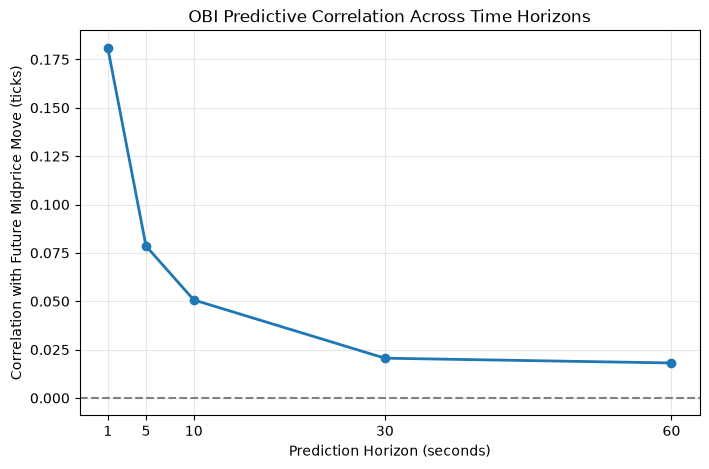

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Horizon (seconds)"],
    results_df["Correlation"],
    marker="o",
    linewidth=2,
)

plt.xlabel("Prediction Horizon (seconds)")
plt.ylabel("Correlation with Future Midprice Move (ticks)")
plt.title("OBI Predictive Correlation Across Time Horizons")
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(horizons)
plt.grid(alpha=0.3)

plt.show()

### 5. Comparing OBI and Microprice Predictive Power

Construct a microprice-based signal and compare its predictive correlations with those of OBI across identical forecast horizons.

This evaluates whether the two order book features exhibit different standalone predictive relationships.

**Research Question:** RQ2 — Incremental Information

In [7]:
# Calculate microprice using existing project function
df["microprice"] = calculate_microprice(
    df["bid_px"],
    df["ask_px"],
    df["bid_sz"],
    df["ask_sz"],
)

# Normalize microprice deviation in basis points
df["microprice_signal"] = (df["microprice"] - df["midprice"]) / df["midprice"] * 10_000

# Sample once per second
signal_df = df[["midprice", "obi", "microprice_signal"]].resample("1s").last().ffill()

# Compare predictive correlations
results = []

for horizon in [1, 5, 10, 30, 60]:
    future_move_ticks = (
        signal_df["midprice"].shift(-horizon) - signal_df["midprice"]
    ) / 0.25

    results.append(
        {
            "Horizon": horizon,
            "OBI": signal_df["obi"].corr(future_move_ticks),
            "Microprice": signal_df["microprice_signal"].corr(future_move_ticks),
        }
    )

comparison_df = pd.DataFrame(results)
print(comparison_df)

   Horizon       OBI  Microprice
0        1  0.180906    0.180861
1        5  0.078546    0.078966
2       10  0.050687    0.050752
3       30  0.020579    0.020726
4       60  0.018107    0.017977


### 5.1 Correlation Between OBI and Microprice

Examine the relationship between OBI and microprice deviation. These signals are mathematically related through the bid-ask spread:

$$
\mathrm{Microprice} - \mathrm{Midprice}
= \frac{\mathrm{Spread}}{2} \times \mathrm{OBI}
$$

Because the spread is typically one tick, their high correlation is expected from the feature definitions rather than an independent empirical finding. Incremental predictive value will be evaluated using distinct signals, such as OFI.

In [8]:
signal_correlation = signal_df["obi"].corr(signal_df["microprice_signal"])

print(f"OBI–Microprice signal correlation: {signal_correlation:.4f}")

OBI–Microprice signal correlation: 0.9988


### 6. Preliminary Execution Feasibility

Compare average absolute future midprice movements against the average quoted bid-ask spread at different prediction horizons.

This provides an initial assessment of whether typical price movements are large enough to warrant further investigation of executable trading strategies.

**Research Question:** RQ4 — Tradability

In [9]:
# Calculate the quoted bid-ask spread
df["spread"] = calculate_spread(df["bid_px"], df["ask_px"])

# Sample the latest observation each second
spread_df = df[["midprice", "spread"]].resample("1s").last().ffill()

# Compare future midprice movements and spreads in ES ticks
tick_size = 0.25
tick_results = []

for h in [1, 5, 10, 30, 60]:
    future_move_ticks = (
        spread_df["midprice"].shift(-h) - spread_df["midprice"]
    ) / tick_size

    spread_ticks = spread_df["spread"] / tick_size

    tick_results.append(
        {
            "Horizon": h,
            "Avg Absolute Move (ticks)": future_move_ticks.abs().mean(),
            "Avg Spread (ticks)": spread_ticks.mean(),
            "Zero Move (%)": (future_move_ticks.dropna() == 0).mean() * 100,
        }
    )

tick_comparison_df = pd.DataFrame(tick_results)

print(tick_comparison_df.round(4))

   Horizon  Avg Absolute Move (ticks)  Avg Spread (ticks)  Zero Move (%)
0        1                     0.6573              1.0216        48.6563
1        5                     1.6408              1.0216        21.5312
2       10                     2.3377              1.0216        15.2079
3       30                     4.0600              1.0216         8.9617
4       60                     5.9234              1.0216         5.9860


### 7. Preliminary Findings and Next Steps

**Key Findings**

- OBI exhibits its strongest predictive correlation at the one-second horizon (approximately 0.181).
- Predictive correlation decreases at longer horizons, reaching approximately 0.018 at 60 seconds.
- Microprice deviation is mathematically related to OBI through the bid-ask spread. Their near-perfect correlation (0.9988) is expected from the feature definitions, particularly when the spread is one tick.
- The average absolute one-second midprice movement is approximately 0.657 ticks, compared with an average quoted spread of 1.022 ticks. Approximately 48.66% of one-second observations show no midprice movement.

**Limitations**

- Results are based on a single trading session.
- Predictive correlations do not establish trading profitability.
- Incremental predictive value has not yet been tested using a joint model.
- Transaction fees, execution delays, and slippage are not included.

**Next Steps**

1. Extend the analysis across multiple trading sessions.
2. Incorporate order flow imbalance (OFI).
3. Evaluate incremental predictive value using combined signals.
4. Develop and backtest trading rules with realistic execution assumptions.